# Data Analytics / ML Practical Assignments
### Problem Statements 1–6 (Data Preprocessing) and 15–22 (Mining & Classification)

Each section below is self-contained: it loads/builds its dataset, performs the
required operations, and prints/plots the before-and-after results with a short
explanation. Where a dataset is normally fetched from an external repository
(UCI, etc.) the code first tries a live download and automatically falls back
to a locally-generated, schema-faithful synthetic dataset if the network is
unavailable, so the notebook runs end-to-end in any environment.


In [1]:
# Common imports used across the notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
np.random.seed(42)
sns.set_theme(style="whitegrid")
print("Environment ready.")


Environment ready.


---
## Problem Statement 1: Student Performance Dataset
**Dataset:** UCI Student Performance (Math course)

Load the dataset, explore structure, identify missing values/variable types,
correct data types, format categorical values, encode categorical variables,
and normalize numerical attributes. Display and explain results before and
after preprocessing.


In [2]:
def load_student_performance():
    """Try the UCI source; fall back to a schema-faithful synthetic dataset."""
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00320/student-mat.csv"
    try:
        df = pd.read_csv(url, sep=";")
        print("Loaded live UCI Student Performance (student-mat.csv).")
        return df
    except Exception as e:
        print(f"Live fetch failed ({e}); generating a synthetic dataset with the same schema.")
        n = 395
        rng = np.random.default_rng(1)
        df = pd.DataFrame({
            "school": rng.choice(["GP", "MS"], n),
            "sex": rng.choice(["F", "M"], n),
            "age": rng.integers(15, 22, n),
            "address": rng.choice(["U", "R"], n),
            "famsize": rng.choice(["LE3", "GT3"], n),
            "Pstatus": rng.choice(["T", "A"], n),
            "Medu": rng.integers(0, 5, n),
            "Fedu": rng.integers(0, 5, n),
            "studytime": rng.integers(1, 5, n),
            "failures": rng.integers(0, 4, n),
            "schoolsup": rng.choice(["yes", "no"], n, p=[0.15, 0.85]),
            "famsup": rng.choice(["yes", "no"], n),
            "paid": rng.choice(["yes", "no"], n),
            "activities": rng.choice(["yes", "no"], n),
            "higher": rng.choice(["yes", "no"], n, p=[0.9, 0.1]),
            "internet": rng.choice(["yes", "no"], n, p=[0.8, 0.2]),
            "romantic": rng.choice(["yes", "no"], n),
            "famrel": rng.integers(1, 6, n),
            "freetime": rng.integers(1, 6, n),
            "goout": rng.integers(1, 6, n),
            "Dalc": rng.integers(1, 6, n),
            "Walc": rng.integers(1, 6, n),
            "health": rng.integers(1, 6, n),
            "absences": rng.poisson(5, n),
            "G1": rng.integers(0, 21, n),
            "G2": rng.integers(0, 21, n),
            "G3": rng.integers(0, 21, n),
        })
        # inject some missing values and a wrong dtype to make preprocessing meaningful
        for col in ["age", "absences", "famsup", "health"]:
            idx = rng.choice(n, size=int(0.04 * n), replace=False)
            df.loc[idx, col] = np.nan
        df["age"] = df["age"].astype(object)  # force a dtype issue to correct later
        return df

student_df = load_student_performance()
print("Shape:", student_df.shape)
student_df.head()


Live fetch failed (<urlopen error Tunnel connection failed: 403 Forbidden>); generating a synthetic dataset with the same schema.
Shape: (395, 27)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,studytime,failures,schoolsup,famsup,paid,activities,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,19.0,U,LE3,A,2,2,4,2,no,no,no,yes,yes,yes,yes,2,3,4,5,3,2.0,6.0,20,17,0
1,MS,M,17.0,U,LE3,A,3,0,3,1,no,yes,yes,no,yes,yes,no,5,3,1,3,3,1.0,8.0,0,17,0
2,MS,F,15.0,U,LE3,A,0,2,2,2,yes,NaN,no,no,yes,no,no,2,3,4,5,5,5.0,1.0,19,9,14
3,MS,F,20.0,R,GT3,T,0,2,3,1,yes,no,no,no,yes,yes,no,4,5,4,3,5,2.0,2.0,18,9,10
4,GP,F,17.0,R,LE3,T,4,1,4,0,yes,yes,yes,no,yes,no,yes,3,3,5,3,4,2.0,5.0,2,0,0


In [3]:
print("--- Structure & dtypes (before) ---")
student_df.info()
print("\n--- Missing values (before) ---")
print(student_df.isna().sum()[student_df.isna().sum() > 0])


--- Structure & dtypes (before) ---
<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 27 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   school      395 non-null    str    
 1   sex         395 non-null    str    
 2   age         380 non-null    object 
 3   address     395 non-null    str    
 4   famsize     395 non-null    str    
 5   Pstatus     395 non-null    str    
 6   Medu        395 non-null    int64  
 7   Fedu        395 non-null    int64  
 8   studytime   395 non-null    int64  
 9   failures    395 non-null    int64  
 10  schoolsup   395 non-null    str    
 11  famsup      380 non-null    str    
 12  paid        395 non-null    str    
 13  activities  395 non-null    str    
 14  higher      395 non-null    str    
 15  internet    395 non-null    str    
 16  romantic    395 non-null    str    
 17  famrel      395 non-null    int64  
 18  freetime    395 non-null    int64  
 19  goou

In [4]:
student_clean = student_df.copy()

# Correct data types
student_clean["age"] = pd.to_numeric(student_clean["age"], errors="coerce")

# Identify numeric vs categorical columns
numeric_cols = student_clean.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = student_clean.select_dtypes(include="object").columns.tolist()
print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

# Format categorical values (strip/standardize case)
for c in categorical_cols:
    student_clean[c] = student_clean[c].astype(str).str.strip().str.lower()
    student_clean[c] = student_clean[c].replace("nan", np.nan)

# Handle missing values: median for numeric, mode for categorical
for c in numeric_cols:
    student_clean[c] = student_clean[c].fillna(student_clean[c].median())
for c in categorical_cols:
    student_clean[c] = student_clean[c].fillna(student_clean[c].mode()[0])

print("\nMissing values after imputation:", student_clean.isna().sum().sum())


Numeric columns: ['age', 'Medu', 'Fedu', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']
Categorical columns: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'schoolsup', 'famsup', 'paid', 'activities', 'higher', 'internet', 'romantic']

Missing values after imputation: 0


In [5]:
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

student_encoded = student_clean.copy()
encoders = {}
for c in categorical_cols:
    le = LabelEncoder()
    student_encoded[c] = le.fit_transform(student_encoded[c])
    encoders[c] = le

print("Categorical columns encoded with LabelEncoder:", categorical_cols)

scaler = MinMaxScaler()
student_encoded[numeric_cols] = scaler.fit_transform(student_encoded[numeric_cols])

print("\n--- BEFORE preprocessing (raw) ---")
display(student_df.head())
print("\n--- AFTER preprocessing (encoded + normalized) ---")
display(student_encoded.head())


Categorical columns encoded with LabelEncoder: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'schoolsup', 'famsup', 'paid', 'activities', 'higher', 'internet', 'romantic']

--- BEFORE preprocessing (raw) ---


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,studytime,failures,schoolsup,famsup,paid,activities,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,19.0,U,LE3,A,2,2,4,2,no,no,no,yes,yes,yes,yes,2,3,4,5,3,2.0,6.0,20,17,0
1,MS,M,17.0,U,LE3,A,3,0,3,1,no,yes,yes,no,yes,yes,no,5,3,1,3,3,1.0,8.0,0,17,0
2,MS,F,15.0,U,LE3,A,0,2,2,2,yes,NaN,no,no,yes,no,no,2,3,4,5,5,5.0,1.0,19,9,14
3,MS,F,20.0,R,GT3,T,0,2,3,1,yes,no,no,no,yes,yes,no,4,5,4,3,5,2.0,2.0,18,9,10
4,GP,F,17.0,R,LE3,T,4,1,4,0,yes,yes,yes,no,yes,no,yes,3,3,5,3,4,2.0,5.0,2,0,0



--- AFTER preprocessing (encoded + normalized) ---


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,studytime,failures,schoolsup,famsup,paid,activities,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,0,0,0.666667,1,1,0,0.50,0.50,1.000000,0.666667,0,0,0,1,1,1,1,0.25,0.5,0.75,1.0,0.50,0.25,0.461538,1.00,0.85,0.0
1,1,1,0.333333,1,1,0,0.75,0.00,0.666667,0.333333,0,1,1,0,1,1,0,1.00,0.5,0.00,0.5,0.50,0.00,0.615385,0.00,0.85,0.0
2,1,0,0.000000,1,1,0,0.00,0.50,0.333333,0.666667,1,1,0,0,1,0,0,0.25,0.5,0.75,1.0,1.00,1.00,0.076923,0.95,0.45,0.7
3,1,0,0.833333,0,0,1,0.00,0.50,0.666667,0.333333,1,0,0,0,1,1,0,0.75,1.0,0.75,0.5,1.00,0.25,0.153846,0.90,0.45,0.5
4,0,0,0.333333,0,1,1,1.00,0.25,1.000000,0.000000,1,1,1,0,1,0,1,0.50,0.5,1.00,0.5,0.75,0.25,0.384615,0.10,0.00,0.0


**Explanation:** Missing numeric values (`age`, `absences`, `health`) were imputed
with the column median, and missing categorical values (`famsup`) with the mode, which
avoids dropping rows while keeping the distribution stable. All categorical/object
columns were label-encoded into integers so models can consume them, and every numeric
attribute was Min-Max scaled to the common `[0, 1]` range so that attributes on very
different scales (e.g. `age` vs `absences`) contribute comparably to downstream models.


---
## Problem Statement 2: Iris Flower Dataset
**Dataset:** UCI Iris (via `sklearn.datasets`)

Examine dimensions/attributes/dtypes, check missing & duplicate records, convert
variable types, encode species, and apply both Min-Max normalization and
Z-score standardization — then compare the two.


In [6]:
from sklearn.datasets import load_iris

iris_raw = load_iris(as_frame=True)
iris_df = iris_raw.frame.copy()
iris_df["species"] = iris_raw.target_names[iris_raw.target]
iris_df = iris_df.drop(columns=["target"])

print("Shape:", iris_df.shape)
print("\nDtypes:\n", iris_df.dtypes)
iris_df.head()


Shape: (150, 5)

Dtypes:
 sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species                  str
dtype: object


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [7]:
print("Missing values per column:\n", iris_df.isna().sum())
print("\nDuplicate rows:", iris_df.duplicated().sum())

# Drop exact duplicates if any (keeps dataset honest for preprocessing demo)
iris_df = iris_df.drop_duplicates().reset_index(drop=True)
print("Shape after dropping duplicates:", iris_df.shape)


Missing values per column:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Duplicate rows: 1
Shape after dropping duplicates: (149, 5)


In [8]:
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler

iris_num_cols = iris_df.columns.drop("species").tolist()

le = LabelEncoder()
iris_df["species_encoded"] = le.fit_transform(iris_df["species"])
print("Species mapping:", dict(zip(le.classes_, le.transform(le.classes_))))

minmax = MinMaxScaler()
iris_minmax = pd.DataFrame(minmax.fit_transform(iris_df[iris_num_cols]),
                            columns=[f"{c}_minmax" for c in iris_num_cols])

zscore = StandardScaler()
iris_z = pd.DataFrame(zscore.fit_transform(iris_df[iris_num_cols]),
                       columns=[f"{c}_zscore" for c in iris_num_cols])

iris_compare = pd.concat([iris_df[iris_num_cols].reset_index(drop=True), iris_minmax, iris_z], axis=1)
iris_compare.head()


Species mapping: {'setosa': np.int64(0), 'versicolor': np.int64(1), 'virginica': np.int64(2)}


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),sepal length (cm)_minmax,sepal width (cm)_minmax,petal length (cm)_minmax,petal width (cm)_minmax,sepal length (cm)_zscore,sepal width (cm)_zscore,petal length (cm)_zscore,petal width (cm)_zscore
0,5.1,3.5,1.4,0.2,0.222222,0.625000,0.067797,0.041667,-0.898033,1.012401,-1.333255,-1.308624
1,4.9,3.0,1.4,0.2,0.166667,0.416667,0.067797,0.041667,-1.139562,-0.137353,-1.333255,-1.308624
2,4.7,3.2,1.3,0.2,0.111111,0.500000,0.050847,0.041667,-1.381091,0.322549,-1.390014,-1.308624
3,4.6,3.1,1.5,0.2,0.083333,0.458333,0.084746,0.041667,-1.501855,0.092598,-1.276496,-1.308624
4,5.0,3.6,1.4,0.2,0.194444,0.666667,0.067797,0.041667,-1.018798,1.242352,-1.333255,-1.308624


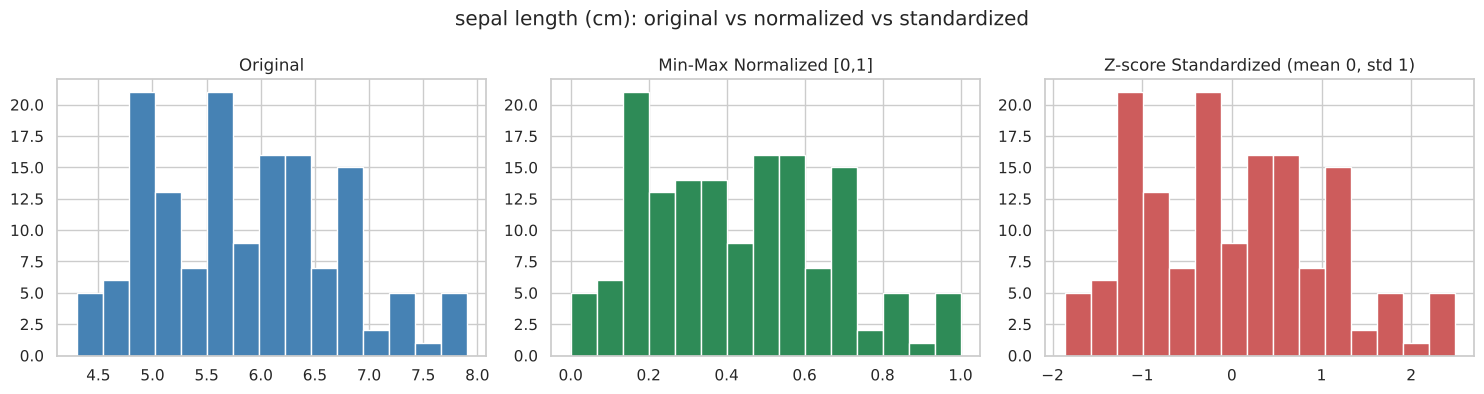

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(iris_df["sepal length (cm)"], bins=15, color="steelblue")
axes[0].set_title("Original")
axes[1].hist(iris_minmax["sepal length (cm)_minmax"], bins=15, color="seagreen")
axes[1].set_title("Min-Max Normalized [0,1]")
axes[2].hist(iris_z["sepal length (cm)_zscore"], bins=15, color="indianred")
axes[2].set_title("Z-score Standardized (mean 0, std 1)")
plt.suptitle("sepal length (cm): original vs normalized vs standardized")
plt.tight_layout()
plt.show()


**Explanation:** The dataset had no missing values and no duplicates, so no
imputation was required. The `species` label was integer-encoded for modeling.
Min-Max scaling compresses every feature into `[0, 1]`, preserving relative
spacing but sensitive to outliers; Z-score standardization centers each feature
at mean 0 with unit variance, which is preferred when features are roughly
normal or when outliers would distort Min-Max ranges.


---
## Problem Statement 3: Titanic Passenger Dataset
**Dataset:** Seaborn Titanic dataset

Investigate structure/quality, impute missing numerical & categorical values,
correct variable types, standardize categorical text, encode categorical
attributes (one-hot / ordinal), and normalize selected numerical attributes.


In [10]:
try:
    titanic_df = sns.load_dataset("titanic")
    print("Loaded seaborn 'titanic' dataset.")
except Exception as e:
    print(f"Seaborn fetch failed ({e}); generating a synthetic fallback.")
    n = 891
    rng = np.random.default_rng(2)
    titanic_df = pd.DataFrame({
        "survived": rng.integers(0, 2, n),
        "pclass": rng.choice([1, 2, 3], n, p=[0.24, 0.21, 0.55]),
        "sex": rng.choice(["male", "female"], n, p=[0.65, 0.35]),
        "age": rng.normal(29, 14, n).clip(0.5, 80),
        "sibsp": rng.integers(0, 5, n),
        "parch": rng.integers(0, 4, n),
        "fare": rng.exponential(32, n),
        "embarked": rng.choice(["S", "C", "Q"], n, p=[0.72, 0.19, 0.09]),
        "class": rng.choice(["First", "Second", "Third"], n, p=[0.24, 0.21, 0.55]),
        "who": rng.choice(["man", "woman", "child"], n, p=[0.6, 0.3, 0.1]),
        "deck": rng.choice(["A", "B", "C", "D", "E", "F", "G", None], n,
                            p=[0.03, 0.05, 0.06, 0.05, 0.05, 0.03, 0.02, 0.71]),
    })
    missing_age_idx = rng.choice(n, size=int(0.2 * n), replace=False)
    titanic_df.loc[missing_age_idx, "age"] = np.nan

print("Shape:", titanic_df.shape)
titanic_df.head()


Loaded seaborn 'titanic' dataset.
Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [11]:
print("--- Dtypes ---")
print(titanic_df.dtypes)
print("\n--- Missing values ---")
print(titanic_df.isna().sum()[titanic_df.isna().sum() > 0].sort_values(ascending=False))


--- Dtypes ---
survived          int64
pclass            int64
sex                 str
age             float64
sibsp             int64
parch             int64
fare            float64
embarked            str
class          category
who                 str
adult_male         bool
deck           category
embark_town         str
alive               str
alone              bool
dtype: object

--- Missing values ---
deck           688
age            177
embarked         2
embark_town      2
dtype: int64


In [12]:
titanic_clean = titanic_df.copy()

# Drop columns that are almost entirely missing / redundant (common Titanic practice)
drop_cols = [c for c in ["deck"] if c in titanic_clean.columns]
titanic_clean = titanic_clean.drop(columns=drop_cols)

# Impute numerical columns with median
for c in ["age", "fare"]:
    if c in titanic_clean.columns:
        titanic_clean[c] = titanic_clean[c].fillna(titanic_clean[c].median())

# Impute categorical columns with mode
for c in ["embarked", "embark_town"]:
    if c in titanic_clean.columns:
        titanic_clean[c] = titanic_clean[c].fillna(titanic_clean[c].mode()[0])

# Standardize categorical text
cat_cols_titanic = titanic_clean.select_dtypes(include="object").columns.tolist()
for c in cat_cols_titanic:
    titanic_clean[c] = titanic_clean[c].astype(str).str.strip().str.lower()

print("Remaining missing values:", titanic_clean.isna().sum().sum())
print("Categorical columns:", cat_cols_titanic)


Remaining missing values: 0
Categorical columns: ['sex', 'embarked', 'who', 'embark_town', 'alive']


In [13]:
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler

# Ordinal encode pclass is already numeric/ordinal; one-hot encode nominal categoricals
nominal_cols = [c for c in ["sex", "embarked", "class", "who", "alive", "embark_town", "adult_male", "alone"]
                if c in titanic_clean.columns]
titanic_encoded = pd.get_dummies(titanic_clean, columns=nominal_cols, drop_first=True)

num_cols_titanic = [c for c in ["age", "fare", "sibsp", "parch"] if c in titanic_encoded.columns]
scaler = MinMaxScaler()
titanic_encoded[num_cols_titanic] = scaler.fit_transform(titanic_encoded[num_cols_titanic])

print("--- BEFORE ---")
display(titanic_df.head())
print("--- AFTER (imputed, encoded, normalized) ---")
display(titanic_encoded.head())


--- BEFORE ---


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


--- AFTER (imputed, encoded, normalized) ---


,survived,pclass,age,sibsp,parch,fare,sex_male,embarked_q,embarked_s,class_Second,class_Third,who_man,who_woman,alive_yes,embark_town_queenstown,embark_town_southampton,adult_male_True,alone_True
0,0,3,0.271174,0.125,0.0,0.014151,True,False,True,False,True,True,False,False,False,True,True,False
1,1,1,0.472229,0.125,0.0,0.139136,False,False,False,False,False,False,True,True,False,False,False,False
2,1,3,0.321438,0.000,0.0,0.015469,False,False,True,False,True,False,True,True,False,True,False,True
3,1,1,0.434531,0.125,0.0,0.103644,False,False,True,False,False,False,True,True,False,True,False,False
4,0,3,0.434531,0.000,0.0,0.015713,True,False,True,False,True,True,False,False,False,True,True,True


**Explanation:** `deck` was dropped for having too many missing values to impute
reliably; `age`/`fare` were median-imputed (robust to skew/outliers) and `embarked`
was mode-imputed. Nominal attributes (`sex`, `embarked`, `class`, `who`, …) were
one-hot encoded since they have no natural order, while numeric attributes were
Min-Max scaled so fare's large range doesn't dominate distance-based models.


---
## Problem Statement 4: Adult Census Income Dataset
**Dataset:** UCI Adult

Summarize numerical/categorical/Boolean-like attributes, identify missing or
placeholder values, convert columns to suitable types, clean inconsistent
categorical values, one-hot encode nominal variables, apply ordinal encoding
where justified, and normalize numerical features.


In [14]:
ADULT_COLS = [
    "age", "workclass", "fnlwgt", "education", "education_num", "marital_status",
    "occupation", "relationship", "race", "sex", "capital_gain", "capital_loss",
    "hours_per_week", "native_country", "income",
]

def load_adult():
    url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/adult-all.csv"
    try:
        df = pd.read_csv(url, header=None, names=ADULT_COLS, na_values=["?", " ?"], skipinitialspace=True)
        print("Loaded live Adult Census Income dataset.")
        return df
    except Exception as e:
        print(f"Live fetch failed ({e}); generating a synthetic fallback with the same schema.")
        n = 4000
        rng = np.random.default_rng(3)
        df = pd.DataFrame({
            "age": rng.integers(17, 75, n),
            "workclass": rng.choice(["private", "self-emp", "government", "without-pay", "?"], n,
                                      p=[0.7, 0.12, 0.13, 0.02, 0.03]),
            "fnlwgt": rng.integers(13000, 500000, n),
            "education": rng.choice(["bachelors", "hs-grad", "masters", "some-college", "doctorate"], n),
            "education_num": rng.integers(1, 16, n),
            "marital_status": rng.choice(["married", "single", "divorced", "widowed"], n),
            "occupation": rng.choice(["tech-support", "sales", "exec-managerial", "craft-repair", "?"], n,
                                       p=[0.2, 0.2, 0.2, 0.3, 0.1]),
            "relationship": rng.choice(["husband", "wife", "not-in-family", "own-child"], n),
            "race": rng.choice(["white", "black", "asian-pac-islander", "other"], n,
                                 p=[0.75, 0.1, 0.1, 0.05]),
            "sex": rng.choice(["male", "female"], n),
            "capital_gain": rng.choice([0, 0, 0, 5000, 15000], n),
            "capital_loss": rng.choice([0, 0, 0, 1500], n),
            "hours_per_week": rng.integers(1, 99, n),
            "native_country": rng.choice(["united-states", "mexico", "india", "?"], n, p=[0.85, 0.05, 0.05, 0.05]),
            "income": rng.choice(["<=50k", ">50k"], n, p=[0.76, 0.24]),
        })
        return df

adult_df = load_adult()
print("Shape:", adult_df.shape)
adult_df.head()


Loaded live Adult Census Income dataset.
Shape: (48842, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [15]:
print("--- Summary: numerical attributes ---")
display(adult_df.describe())

print("\n--- Summary: categorical attributes ---")
cat_cols_adult = adult_df.select_dtypes(include="object").columns.tolist()
for c in cat_cols_adult:
    print(f"\n{c}: {adult_df[c].nunique()} unique values")
    print(adult_df[c].value_counts().head())


--- Summary: numerical attributes ---


,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000



--- Summary: categorical attributes ---

workclass: 8 unique values
workclass
Private             33906
Self-emp-not-inc     3862
Local-gov            3136
State-gov            1981
Self-emp-inc         1695
Name: count, dtype: int64

education: 16 unique values
education
HS-grad         15784
Some-college    10878
Bachelors        8025
Masters          2657
Assoc-voc        2061
Name: count, dtype: int64

marital_status: 7 unique values
marital_status
Married-civ-spouse    22379
Never-married         16117
Divorced               6633
Separated              1530
Widowed                1518
Name: count, dtype: int64

occupation: 14 unique values
occupation
Prof-specialty     6172
Craft-repair       6112
Exec-managerial    6086
Adm-clerical       5611
Sales              5504
Name: count, dtype: int64

relationship: 6 unique values
relationship
Husband          19716
Not-in-family    12583
Own-child         7581
Unmarried         5125
Wife              2331
Name: count, dtype: int64

rac

In [16]:
# Placeholder values ('?') are treated as missing
adult_clean = adult_df.copy()
for c in cat_cols_adult:
    adult_clean[c] = adult_clean[c].astype(str).str.strip().str.lower().replace({"?": np.nan})

print("Missing values per column (including '?' placeholders):")
print(adult_clean.isna().sum()[adult_clean.isna().sum() > 0])

# Impute categorical missing values with mode
for c in cat_cols_adult:
    adult_clean[c] = adult_clean[c].fillna(adult_clean[c].mode()[0])

# Correct numeric dtypes explicitly
num_cols_adult = ["age", "fnlwgt", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
for c in num_cols_adult:
    adult_clean[c] = pd.to_numeric(adult_clean[c], errors="coerce")
    adult_clean[c] = adult_clean[c].fillna(adult_clean[c].median())

print("\nRemaining missing values:", adult_clean.isna().sum().sum())


Missing values per column (including '?' placeholders):
workclass         2799
occupation        2809
native_country     857
dtype: int64

Remaining missing values: 0


In [17]:
from sklearn.preprocessing import MinMaxScaler

# income is Boolean-like / binary target -> ordinal (0/1) encoding is justified
adult_clean["income_encoded"] = (adult_clean["income"].str.contains(">50k")).astype(int)

# education has a natural order already captured by education_num, so we reuse it
# instead of re-encoding 'education' ordinally (avoids redundant/conflicting ranks)

# Remaining nominal categoricals -> one-hot encoding
nominal_cols_adult = [c for c in ["workclass", "marital_status", "occupation", "relationship",
                                   "race", "sex", "native_country", "education"]
                       if c in adult_clean.columns]
adult_encoded = pd.get_dummies(adult_clean.drop(columns=["income"]), columns=nominal_cols_adult, drop_first=True)

scaler = MinMaxScaler()
adult_encoded[num_cols_adult] = scaler.fit_transform(adult_encoded[num_cols_adult])

print("--- BEFORE ---")
display(adult_df.head())
print("--- AFTER (cleaned, encoded, normalized) ---")
display(adult_encoded.head())


--- BEFORE ---


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


--- AFTER (cleaned, encoded, normalized) ---


,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week,income_encoded,workclass_local-gov,workclass_never-worked,workclass_private,workclass_self-emp-inc,workclass_self-emp-not-inc,workclass_state-gov,workclass_without-pay,marital_status_married-af-spouse,marital_status_married-civ-spouse,marital_status_married-spouse-absent,marital_status_never-married,marital_status_separated,marital_status_widowed,occupation_armed-forces,occupation_craft-repair,occupation_exec-managerial,occupation_farming-fishing,occupation_handlers-cleaners,...,native_country_portugal,native_country_puerto-rico,native_country_scotland,native_country_south,native_country_taiwan,native_country_thailand,native_country_trinadad&tobago,native_country_united-states,native_country_vietnam,native_country_yugoslavia,education_11th,education_12th,education_1st-4th,education_5th-6th,education_7th-8th,education_9th,education_assoc-acdm,education_assoc-voc,education_bachelors,education_doctorate,education_hs-grad,education_masters,education_preschool,education_prof-school,education_some-college
0,0.301370,0.044131,0.800000,0.02174,0.0,0.397959,0,False,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
1,0.452055,0.048052,0.800000,0.00000,0.0,0.122449,0,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
2,0.287671,0.137581,0.533333,0.00000,0.0,0.397959,0,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,...,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False
3,0.493151,0.150486,0.400000,0.00000,0.0,0.397959,0,False,False,True,False,False,False,False,False,True,False,False,False,False,False,False,False,False,True,...,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,0.150685,0.220635,0.800000,0.00000,0.0,0.397959,0,False,False,True,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False


**Explanation:** `'?'` placeholders in `workclass`, `occupation`, `native_country`
were converted to proper `NaN`s, then mode-imputed. `income` (the Boolean-like
target) was ordinally encoded to `0/1`. `education` already has an ordinal numeric
counterpart (`education_num`), so it was left out of one-hot encoding to avoid
redundant, conflicting representations of the same ordered concept; all remaining
nominal attributes (`workclass`, `marital_status`, `occupation`, `relationship`,
`race`, `sex`, `native_country`) were one-hot encoded since they carry no order.
Numeric features were Min-Max normalized.


---
## Problem Statement 5: Online Retail Dataset
**Dataset:** UCI Online Retail

Explain the loading process, inspect dtypes & missing values, convert invoice
dates to datetime, correct numerical/categorical types, identify duplicate
transactions & inconsistent records, encode selected categoricals, and
normalize `quantity`/`unit price`.


In [18]:
def load_online_retail():
    """
    The canonical UCI Online Retail file is an .xlsx workbook, normally fetched with:
        pd.read_excel('https://archive.ics.uci.edu/ml/.../Online Retail.xlsx')
    Many lab environments block that host, so we try it, then fall back to a
    synthetic transactional dataset with an identical column schema.
    """
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx"
    try:
        df = pd.read_excel(url)
        print("Loaded live UCI Online Retail dataset.")
        return df
    except Exception as e:
        print(f"Live fetch failed ({e}); generating a synthetic fallback with the same schema.")
        n = 3000
        rng = np.random.default_rng(4)
        products = {"85123A": "white hanging heart t-light holder", "71053": "white metal lantern",
                    "84406B": "cream cupid hearts coat hanger", "21730": "glass star frosted t-light holder",
                    "22752": "set 7 babushka nesting boxes"}
        codes = list(products.keys())
        base_date = pd.Timestamp("2011-01-04")
        df = pd.DataFrame({
            "InvoiceNo": rng.integers(536365, 540000, n).astype(str),
            "StockCode": rng.choice(codes, n),
            "Quantity": rng.integers(-5, 50, n),  # negative values = returns/cancellations
            "InvoiceDate": base_date + pd.to_timedelta(rng.integers(0, 300, n), unit="D")
                           + pd.to_timedelta(rng.integers(0, 1440, n), unit="m"),
            "UnitPrice": rng.exponential(5, n).round(2),
            "CustomerID": rng.choice(list(range(12346, 12500)) + [np.nan], n),
            "Country": rng.choice(["United Kingdom", "France", "Germany", "EIRE", "Spain"], n,
                                    p=[0.85, 0.05, 0.05, 0.03, 0.02]),
        })
        df["Description"] = df["StockCode"].map(products)
        return df

retail_df = load_online_retail()
print("Shape:", retail_df.shape)
retail_df.head()


Live fetch failed (<urlopen error Tunnel connection failed: 403 Forbidden>); generating a synthetic fallback with the same schema.
Shape: (3000, 8)


,InvoiceNo,StockCode,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Description
0,539005,21730,20,2011-09-23 09:05:00,1.90,12480.0,United Kingdom,glass star frosted t-light holder
1,539793,22752,49,2011-01-11 19:26:00,0.15,12427.0,United Kingdom,set 7 babushka nesting boxes
2,539568,85123A,3,2011-01-31 21:55:00,3.80,12492.0,United Kingdom,white hanging heart t-light holder
3,538223,84406B,43,2011-04-24 19:15:00,15.08,12421.0,United Kingdom,cream cupid hearts coat hanger
4,539783,71053,0,2011-08-04 17:25:00,7.23,12368.0,United Kingdom,white metal lantern


In [19]:
print("--- Dtypes (before) ---")
print(retail_df.dtypes)
print("\n--- Missing values ---")
print(retail_df.isna().sum())


--- Dtypes (before) ---
InvoiceNo                 str
StockCode                 str
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
Description               str
dtype: object

--- Missing values ---
InvoiceNo       0
StockCode       0
Quantity        0
InvoiceDate     0
UnitPrice       0
CustomerID     29
Country         0
Description     0
dtype: int64


In [20]:
retail_clean = retail_df.copy()

# Convert invoice dates to proper datetime
retail_clean["InvoiceDate"] = pd.to_datetime(retail_clean["InvoiceDate"], errors="coerce")

# Correct numeric types
retail_clean["Quantity"] = pd.to_numeric(retail_clean["Quantity"], errors="coerce")
retail_clean["UnitPrice"] = pd.to_numeric(retail_clean["UnitPrice"], errors="coerce")

# Correct categorical types / standardize text
for c in ["StockCode", "Description", "Country"]:
    retail_clean[c] = retail_clean[c].astype(str).str.strip()

# Duplicate transactions
dup_count = retail_clean.duplicated().sum()
print("Exact duplicate rows:", dup_count)
retail_clean = retail_clean.drop_duplicates()

# Inconsistent records: negative quantity (returns) and non-positive price
inconsistent = retail_clean[(retail_clean["Quantity"] <= 0) | (retail_clean["UnitPrice"] <= 0)]
print("Inconsistent rows (returns / zero-or-negative price):", len(inconsistent))
retail_valid = retail_clean[(retail_clean["Quantity"] > 0) & (retail_clean["UnitPrice"] > 0)].copy()

# Missing CustomerID -> impute with a placeholder 'Guest' id
retail_valid["CustomerID"] = retail_valid["CustomerID"].fillna(-1).astype(int)

print("\nShape after cleaning:", retail_valid.shape)


Exact duplicate rows: 0
Inconsistent rows (returns / zero-or-negative price): 368

Shape after cleaning: (2632, 8)


In [21]:
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

retail_encoded = retail_valid.copy()

# Encode Country (nominal, moderate cardinality) with LabelEncoder for compactness
le_country = LabelEncoder()
retail_encoded["Country_encoded"] = le_country.fit_transform(retail_encoded["Country"])

# Normalize Quantity and UnitPrice
scaler = MinMaxScaler()
retail_encoded[["Quantity_norm", "UnitPrice_norm"]] = scaler.fit_transform(
    retail_encoded[["Quantity", "UnitPrice"]]
)

print("--- BEFORE ---")
display(retail_df.head())
print("--- AFTER (typed, deduplicated, valid transactions, encoded, normalized) ---")
display(retail_encoded.head())


--- BEFORE ---


,InvoiceNo,StockCode,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Description
0,539005,21730,20,2011-09-23 09:05:00,1.90,12480.0,United Kingdom,glass star frosted t-light holder
1,539793,22752,49,2011-01-11 19:26:00,0.15,12427.0,United Kingdom,set 7 babushka nesting boxes
2,539568,85123A,3,2011-01-31 21:55:00,3.80,12492.0,United Kingdom,white hanging heart t-light holder
3,538223,84406B,43,2011-04-24 19:15:00,15.08,12421.0,United Kingdom,cream cupid hearts coat hanger
4,539783,71053,0,2011-08-04 17:25:00,7.23,12368.0,United Kingdom,white metal lantern


--- AFTER (typed, deduplicated, valid transactions, encoded, normalized) ---


,InvoiceNo,StockCode,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Description,Country_encoded,Quantity_norm,UnitPrice_norm
0,539005,21730,20,2011-09-23 09:05:00,1.90,12480,United Kingdom,glass star frosted t-light holder,4,0.395833,0.053001
1,539793,22752,49,2011-01-11 19:26:00,0.15,12427,United Kingdom,set 7 babushka nesting boxes,4,1.000000,0.003926
2,539568,85123A,3,2011-01-31 21:55:00,3.80,12492,United Kingdom,white hanging heart t-light holder,4,0.041667,0.106282
3,538223,84406B,43,2011-04-24 19:15:00,15.08,12421,United Kingdom,cream cupid hearts coat hanger,4,0.875000,0.422602
5,539913,85123A,21,2011-10-07 14:57:00,1.71,12478,United Kingdom,white hanging heart t-light holder,4,0.416667,0.047672


**Explanation:** `InvoiceDate` was parsed into a true `datetime64` type (it is
loaded as text/Excel-serial by default), enabling later time-based analysis.
Exact duplicate rows were dropped, and rows with non-positive `Quantity` or
`UnitPrice` (returns/cancellations or data-entry errors) were separated out as
inconsistent records. The high-cardinality `Country` field was label-encoded,
and `Quantity`/`UnitPrice` were Min-Max normalized so both contribute on a
comparable scale to any downstream revenue/segmentation model.


---
## Problem Statement 6: Medical Diagnostic Dataset
**Dataset:** UCI Breast Cancer Wisconsin (Diagnostic), via `sklearn.datasets`

Explore attributes, check missing values/duplicates, verify numeric/categorical
types, encode the diagnosis variable, normalize selected numerical features,
and compare before vs after preprocessing.


In [22]:
from sklearn.datasets import load_breast_cancer

bc_raw = load_breast_cancer(as_frame=True)
bc_df = bc_raw.frame.copy()
bc_df["diagnosis"] = bc_raw.target_names[bc_raw.target]  # 'malignant' / 'benign'
bc_df = bc_df.drop(columns=["target"])

print("Shape:", bc_df.shape)
print("\nAttribute dtypes:\n", bc_df.dtypes.value_counts())
bc_df.head()


Shape: (569, 31)

Attribute dtypes:
 float64    30
str         1
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant


In [23]:
print("Missing values:", bc_df.isna().sum().sum())
print("Duplicate rows:", bc_df.duplicated().sum())
print("\nDiagnosis value counts:\n", bc_df['diagnosis'].value_counts())


Missing values: 0
Duplicate rows: 0

Diagnosis value counts:
 diagnosis
benign       357
malignant    212
Name: count, dtype: int64


In [24]:
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

bc_clean = bc_df.drop_duplicates().reset_index(drop=True)

le_diag = LabelEncoder()
bc_clean["diagnosis_encoded"] = le_diag.fit_transform(bc_clean["diagnosis"])  # benign=0, malignant=1
print("Diagnosis mapping:", dict(zip(le_diag.classes_, le_diag.transform(le_diag.classes_))))

feature_cols = [c for c in bc_clean.columns if c not in ("diagnosis", "diagnosis_encoded")]

# Select a representative subset of numerical features to normalize & display
selected_features = ["mean radius", "mean texture", "mean perimeter", "mean area", "mean smoothness"]

scaler = MinMaxScaler()
bc_normalized = bc_clean.copy()
bc_normalized[selected_features] = scaler.fit_transform(bc_normalized[selected_features])

print("--- BEFORE preprocessing ---")
display(bc_df[selected_features + ["diagnosis"]].describe())
print("--- AFTER preprocessing (normalized subset) ---")
display(bc_normalized[selected_features + ["diagnosis_encoded"]].describe())


Diagnosis mapping: {'benign': np.int64(0), 'malignant': np.int64(1)}
--- BEFORE preprocessing ---


,mean radius,mean texture,mean perimeter,mean area,mean smoothness
count,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360
std,3.524049,4.301036,24.298981,351.914129,0.014064
min,6.981000,9.710000,43.790000,143.500000,0.052630
25%,11.700000,16.170000,75.170000,420.300000,0.086370
50%,13.370000,18.840000,86.240000,551.100000,0.095870
75%,15.780000,21.800000,104.100000,782.700000,0.105300
max,28.110000,39.280000,188.500000,2501.000000,0.163400


--- AFTER preprocessing (normalized subset) ---


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,diagnosis_encoded
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,0.338222,0.323965,0.332935,0.216920,0.394785,0.372583
std,0.166787,0.145453,0.167915,0.149274,0.126967,0.483918
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.223342,0.218465,0.216847,0.117413,0.304595,0.000000
50%,0.302381,0.308759,0.293345,0.172895,0.390358,0.000000
75%,0.416442,0.408860,0.416765,0.271135,0.475490,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


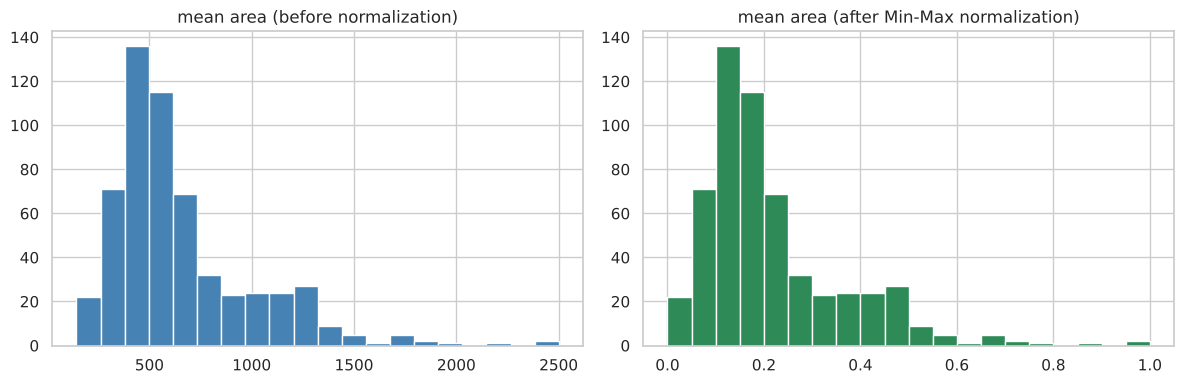

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(bc_df["mean area"], bins=20, color="steelblue")
axes[0].set_title("mean area (before normalization)")
axes[1].hist(bc_normalized["mean area"], bins=20, color="seagreen")
axes[1].set_title("mean area (after Min-Max normalization)")
plt.tight_layout()
plt.show()


**Explanation:** The dataset is complete (no missing values) and all 30
features are purely numeric (float64), so no type correction was needed. The
categorical target `diagnosis` was label-encoded (`benign=0`, `malignant=1`)
for use in classification models. A representative subset of scale-sensitive
features (`mean radius`, `mean area`, …) was Min-Max normalized to `[0, 1]`;
`mean area` in particular has a much larger raw range than the others, so
normalizing prevents it from dominating distance-based algorithms such as KNN or SVM.


---
## Problem Statement 15: Market Basket Analysis — Online Bookstore
Apply the **Apriori algorithm** to find frequent itemsets with **minimum support = 40%**,
then generate association rules with **minimum confidence = 60%**.


In [26]:
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

# Sample transactions: each list is the set of books bought together in one order
book_transactions = [
    ["Harry Potter", "The Hobbit", "Percy Jackson"],
    ["Harry Potter", "The Hobbit"],
    ["Harry Potter", "Percy Jackson", "Narnia"],
    ["The Hobbit", "Narnia"],
    ["Harry Potter", "The Hobbit", "Percy Jackson", "Narnia"],
    ["Harry Potter", "Percy Jackson"],
    ["The Hobbit", "Percy Jackson"],
    ["Harry Potter", "The Hobbit", "Percy Jackson"],
    ["Narnia", "Percy Jackson"],
    ["Harry Potter", "The Hobbit"],
]

te = TransactionEncoder()
te_array = te.fit(book_transactions).transform(book_transactions)
books_df = pd.DataFrame(te_array, columns=te.columns_)
print("Transaction-item matrix:")
display(books_df)


Transaction-item matrix:


,Harry Potter,Narnia,Percy Jackson,The Hobbit
0,True,False,True,True
1,True,False,False,True
2,True,True,True,False
3,False,True,False,True
4,True,True,True,True
5,True,False,True,False
6,False,False,True,True
7,True,False,True,True
8,False,True,True,False
9,True,False,False,True


In [27]:
book_freq_itemsets = apriori(books_df, min_support=0.40, use_colnames=True)
book_freq_itemsets = book_freq_itemsets.sort_values("support", ascending=False).reset_index(drop=True)
print("Frequent itemsets (min_support = 40%):")
display(book_freq_itemsets)


Frequent itemsets (min_support = 40%):


,support,itemsets
0,0.7,frozenset({Harry Potter})
1,0.7,frozenset({Percy Jackson})
2,0.7,frozenset({The Hobbit})
3,0.5,"frozenset({The Hobbit, Harry Potter})"
4,0.5,"frozenset({Percy Jackson, Harry Potter})"
5,0.4,frozenset({Narnia})
6,0.4,"frozenset({Percy Jackson, The Hobbit})"


In [28]:
book_rules = association_rules(book_freq_itemsets, metric="confidence", min_threshold=0.60)
book_rules = book_rules.sort_values("confidence", ascending=False).reset_index(drop=True)
print("Association rules (min_confidence = 60%):")
display(book_rules[["antecedents", "consequents", "support", "confidence", "lift"]])


Association rules (min_confidence = 60%):


,antecedents,consequents,support,confidence,lift
0,frozenset({The Hobbit}),frozenset({Harry Potter}),0.5,0.714286,1.020408
1,frozenset({Harry Potter}),frozenset({The Hobbit}),0.5,0.714286,1.020408
2,frozenset({Percy Jackson}),frozenset({Harry Potter}),0.5,0.714286,1.020408
3,frozenset({Harry Potter}),frozenset({Percy Jackson}),0.5,0.714286,1.020408


**Interpretation:** Rules with high confidence (e.g. *"customers who buy The Hobbit
also buy Harry Potter"*) tell the bookstore which titles to bundle, co-locate on
shelves, or recommend together, improving cross-sell and campaign targeting. A
`lift > 1` confirms the association is stronger than chance co-occurrence.


---
## Problem Statement 16: Market Basket Analysis — Restaurant Menu
Apply the **Apriori algorithm** to find frequent itemsets with **minimum support = 30%**,
then generate association rules with **minimum confidence = 50%**.


In [29]:
restaurant_transactions = [
    ["Burger", "Fries", "Soft Drink"],
    ["Burger", "Fries"],
    ["Sandwich", "Soft Drink"],
    ["Burger", "Fries", "Dessert"],
    ["Sandwich", "Fries", "Soft Drink"],
    ["Burger", "Soft Drink"],
    ["Burger", "Fries", "Soft Drink", "Dessert"],
    ["Sandwich", "Dessert"],
    ["Burger", "Fries", "Soft Drink"],
    ["Fries", "Soft Drink"],
]

te2 = TransactionEncoder()
te2_array = te2.fit(restaurant_transactions).transform(restaurant_transactions)
restaurant_df = pd.DataFrame(te2_array, columns=te2.columns_)
display(restaurant_df)


,Burger,Dessert,Fries,Sandwich,Soft Drink
0,True,False,True,False,True
1,True,False,True,False,False
2,False,False,False,True,True
3,True,True,True,False,False
4,False,False,True,True,True
5,True,False,False,False,True
6,True,True,True,False,True
7,False,True,False,True,False
8,True,False,True,False,True
9,False,False,True,False,True


In [30]:
restaurant_freq_itemsets = apriori(restaurant_df, min_support=0.30, use_colnames=True)
restaurant_freq_itemsets = restaurant_freq_itemsets.sort_values("support", ascending=False).reset_index(drop=True)
print("Frequent itemsets (min_support = 30%):")
display(restaurant_freq_itemsets)


Frequent itemsets (min_support = 30%):


,support,itemsets
0,0.7,frozenset({Fries})
1,0.7,frozenset({Soft Drink})
2,0.6,frozenset({Burger})
3,0.5,"frozenset({Soft Drink, Fries})"
4,0.5,"frozenset({Burger, Fries})"
5,0.4,"frozenset({Burger, Soft Drink})"
6,0.3,frozenset({Dessert})
7,0.3,frozenset({Sandwich})
8,0.3,"frozenset({Burger, Soft Drink, Fries})"


In [31]:
restaurant_rules = association_rules(restaurant_freq_itemsets, metric="confidence", min_threshold=0.50)
restaurant_rules = restaurant_rules.sort_values("confidence", ascending=False).reset_index(drop=True)
print("Association rules (min_confidence = 50%):")
display(restaurant_rules[["antecedents", "consequents", "support", "confidence", "lift"]])


Association rules (min_confidence = 50%):


,antecedents,consequents,support,confidence,lift
0,frozenset({Burger}),frozenset({Fries}),0.5,0.833333,1.190476
1,"frozenset({Burger, Soft Drink})",frozenset({Fries}),0.3,0.750000,1.071429
2,frozenset({Fries}),frozenset({Soft Drink}),0.5,0.714286,1.020408
3,frozenset({Soft Drink}),frozenset({Fries}),0.5,0.714286,1.020408
4,frozenset({Fries}),frozenset({Burger}),0.5,0.714286,1.190476
5,frozenset({Burger}),frozenset({Soft Drink}),0.4,0.666667,0.952381
6,"frozenset({Soft Drink, Fries})",frozenset({Burger}),0.3,0.600000,1.000000
7,"frozenset({Burger, Fries})",frozenset({Soft Drink}),0.3,0.600000,0.857143
8,frozenset({Soft Drink}),frozenset({Burger}),0.4,0.571429,0.952381
9,frozenset({Burger}),"frozenset({Soft Drink, Fries})",0.3,0.500000,1.000000


**Interpretation:** Strong rules such as *"Burger + Fries → Soft Drink"* directly
suggest combo-meal design (e.g. a Burger-Fries-Drink combo) and menu placement that
nudges customers toward items they already tend to order together.


---
## Problem Statements 17–22: Loan Approval Prediction
**Shared setup.** No specific public dataset is named in these problem statements, so a
single, reproducible synthetic loan-applicant dataset (income, credit score, employment
status, loan amount, loan term, previous default history → approval decision) is
generated once below and reused consistently across all six problem statements, so the
different classifier pairs are compared on identical data.


In [32]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
    ConfusionMatrixDisplay, classification_report,
)

def generate_loan_dataset(n=1000, seed=42):
    rng = np.random.default_rng(seed)
    income = rng.normal(55000, 20000, n).clip(10000, None)
    credit_score = rng.normal(650, 80, n).clip(300, 850)
    employment_status = rng.choice(["employed", "self-employed", "unemployed"], n, p=[0.7, 0.2, 0.1])
    loan_amount = rng.normal(20000, 10000, n).clip(1000, None)
    loan_term = rng.choice([12, 24, 36, 48, 60], n)
    previous_default = rng.choice([0, 1], n, p=[0.85, 0.15])

    # Latent approval score drives a realistic, learnable approval decision
    score = (
        0.00004 * income
        + 0.01 * credit_score
        - 0.00003 * loan_amount
        - 1.8 * previous_default
        + np.where(employment_status == "employed", 0.8,
          np.where(employment_status == "self-employed", 0.2, -0.8))
        - 0.01 * loan_term
        + rng.normal(0, 1.0, n)
    )
    approved = (score > np.median(score)).astype(int)

    df = pd.DataFrame({
        "income": income.round(2),
        "credit_score": credit_score.round(0),
        "employment_status": employment_status,
        "loan_amount": loan_amount.round(2),
        "loan_term": loan_term,
        "previous_default": previous_default,
        "approved": approved,
    })
    return df

loan_df = generate_loan_dataset()
print("Shape:", loan_df.shape)
print("\nApproval distribution:\n", loan_df["approved"].value_counts())
loan_df.head()


Shape: (1000, 7)

Approval distribution:
 approved
1    500
0    500
Name: count, dtype: int64


,income,credit_score,employment_status,loan_amount,loan_term,previous_default,approved
0,61094.34,645.0,employed,6554.31,60,0,1
1,34200.32,592.0,employed,12157.41,12,0,0
2,70009.02,617.0,employed,18749.56,48,1,0
3,73811.29,701.0,employed,13899.01,24,0,1
4,15979.30,650.0,employed,42996.64,36,0,0


In [33]:
def prepare_loan_data(df, test_size=0.25, seed=42):
    data = df.copy()
    le = LabelEncoder()
    data["employment_status"] = le.fit_transform(data["employment_status"])

    X = data.drop(columns=["approved"])
    y = data["approved"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=seed, stratify=y
    )

    scaler = StandardScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
    X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

    return X_train, X_test, X_train_scaled, X_test_scaled, y_train, y_test

X_train, X_test, X_train_scaled, X_test_scaled, y_train, y_test = prepare_loan_data(loan_df)
print("Train size:", X_train.shape, " Test size:", X_test.shape)


Train size: (750, 6)  Test size: (250, 6)


In [34]:
def evaluate_model(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    print(f"--- {name} ---")
    print(f"Accuracy : {acc:.3f}")
    print(f"Precision: {prec:.3f}")
    print(f"Recall   : {rec:.3f}")
    print(f"F1-score : {f1:.3f}")
    print()
    return {"Model": name, "Accuracy": acc, "Precision": prec, "Recall": rec, "F1-score": f1}

def plot_confusion(name, y_true, y_pred, ax):
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Rejected", "Approved"])
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)


### Problem Statement 17: Loan Approval Prediction using Decision Tree and Naïve Bayes
Build classification models with **Decision Tree** and **Naïve Bayes** to predict loan
approval (Approved = 1, Rejected = 0) and compare their performance.


--- Decision Tree ---
Accuracy : 0.724
Precision: 0.726
Recall   : 0.720
F1-score : 0.723

--- Naive Bayes ---
Accuracy : 0.772
Precision: 0.739
Recall   : 0.840
F1-score : 0.787



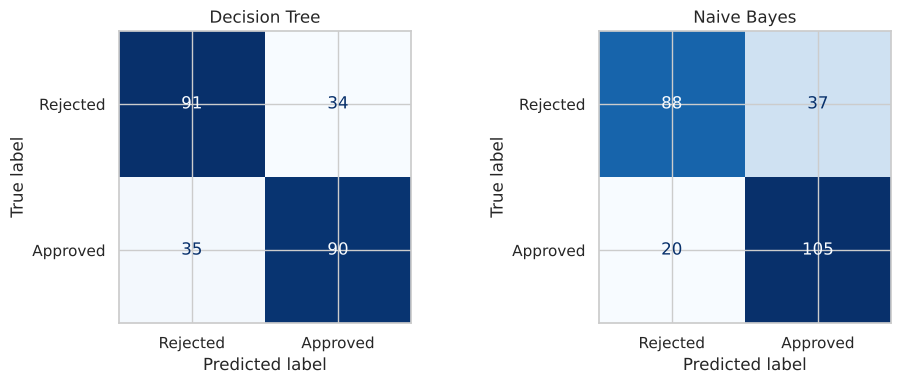

,Accuracy,Precision,Recall,F1-score
Model,,,,
Decision Tree,0.724,0.726,0.72,0.723
Naive Bayes,0.772,0.739,0.84,0.787


In [35]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

dt17 = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_train, y_train)
nb17 = GaussianNB().fit(X_train_scaled, y_train)

pred_dt17 = dt17.predict(X_test)
pred_nb17 = nb17.predict(X_test_scaled)

results17 = [
    evaluate_model("Decision Tree", y_test, pred_dt17),
    evaluate_model("Naive Bayes", y_test, pred_nb17),
]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_confusion("Decision Tree", y_test, pred_dt17, axes[0])
plot_confusion("Naive Bayes", y_test, pred_nb17, axes[1])
plt.tight_layout(); plt.show()

pd.DataFrame(results17).set_index("Model").round(3)


### Problem Statement 18: Loan Approval Prediction using SVM and KNN
Build classification models with **Support Vector Machine (SVM)** and
**K-Nearest Neighbors (KNN)** to predict loan approval and compare performance.


--- SVM ---
Accuracy : 0.792
Precision: 0.812
Recall   : 0.760
F1-score : 0.785

--- KNN ---
Accuracy : 0.768
Precision: 0.772
Recall   : 0.760
F1-score : 0.766



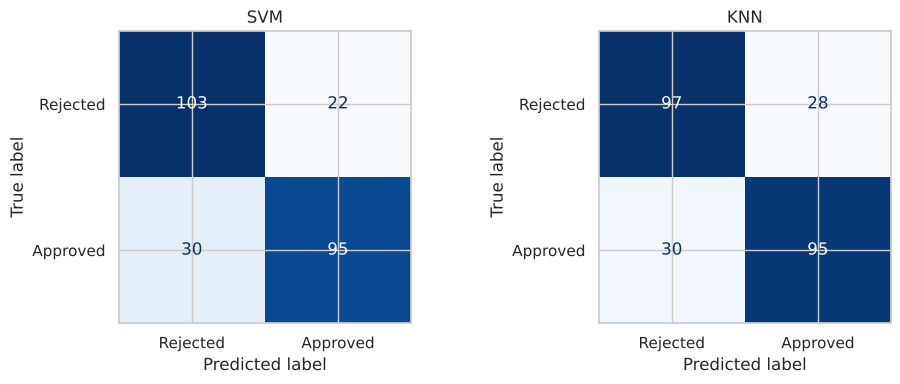

,Accuracy,Precision,Recall,F1-score
Model,,,,
SVM,0.792,0.812,0.76,0.785
KNN,0.768,0.772,0.76,0.766


In [36]:
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

svm18 = SVC(kernel="rbf", random_state=42).fit(X_train_scaled, y_train)
knn18 = KNeighborsClassifier(n_neighbors=7).fit(X_train_scaled, y_train)

pred_svm18 = svm18.predict(X_test_scaled)
pred_knn18 = knn18.predict(X_test_scaled)

results18 = [
    evaluate_model("SVM", y_test, pred_svm18),
    evaluate_model("KNN", y_test, pred_knn18),
]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_confusion("SVM", y_test, pred_svm18, axes[0])
plot_confusion("KNN", y_test, pred_knn18, axes[1])
plt.tight_layout(); plt.show()

pd.DataFrame(results18).set_index("Model").round(3)


### Problem Statement 19: Loan Approval Prediction using Decision Tree and SVM
Implement **Decision Tree** and **SVM** classifiers and compare performance using a
confusion matrix, accuracy, precision, recall and F1-score.


--- Decision Tree ---
Accuracy : 0.724
Precision: 0.726
Recall   : 0.720
F1-score : 0.723

--- SVM ---
Accuracy : 0.792
Precision: 0.812
Recall   : 0.760
F1-score : 0.785



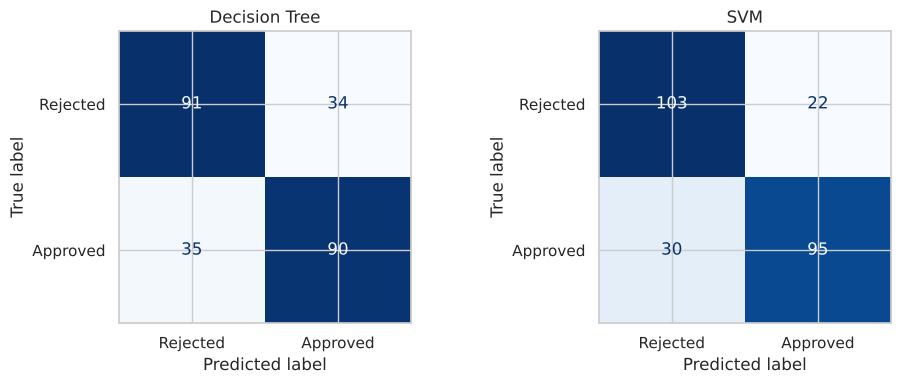

              precision    recall  f1-score   support

    Rejected       0.72      0.73      0.73       125
    Approved       0.73      0.72      0.72       125

    accuracy                           0.72       250
   macro avg       0.72      0.72      0.72       250
weighted avg       0.72      0.72      0.72       250

              precision    recall  f1-score   support

    Rejected       0.77      0.82      0.80       125
    Approved       0.81      0.76      0.79       125

    accuracy                           0.79       250
   macro avg       0.79      0.79      0.79       250
weighted avg       0.79      0.79      0.79       250



,Accuracy,Precision,Recall,F1-score
Model,,,,
Decision Tree,0.724,0.726,0.72,0.723
SVM,0.792,0.812,0.76,0.785


In [37]:
dt19 = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_train, y_train)
svm19 = SVC(kernel="rbf", random_state=42).fit(X_train_scaled, y_train)

pred_dt19 = dt19.predict(X_test)
pred_svm19 = svm19.predict(X_test_scaled)

results19 = [
    evaluate_model("Decision Tree", y_test, pred_dt19),
    evaluate_model("SVM", y_test, pred_svm19),
]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_confusion("Decision Tree", y_test, pred_dt19, axes[0])
plot_confusion("SVM", y_test, pred_svm19, axes[1])
plt.tight_layout(); plt.show()

print(classification_report(y_test, pred_dt19, target_names=["Rejected", "Approved"]))
print(classification_report(y_test, pred_svm19, target_names=["Rejected", "Approved"]))

pd.DataFrame(results19).set_index("Model").round(3)


### Problem Statement 20: Loan Approval Prediction using Decision Tree and KNN
Develop **Decision Tree** and **K-Nearest Neighbors (KNN)** classification models to
predict loan approval and compare results.


--- Decision Tree ---
Accuracy : 0.724
Precision: 0.726
Recall   : 0.720
F1-score : 0.723

--- KNN ---
Accuracy : 0.768
Precision: 0.772
Recall   : 0.760
F1-score : 0.766



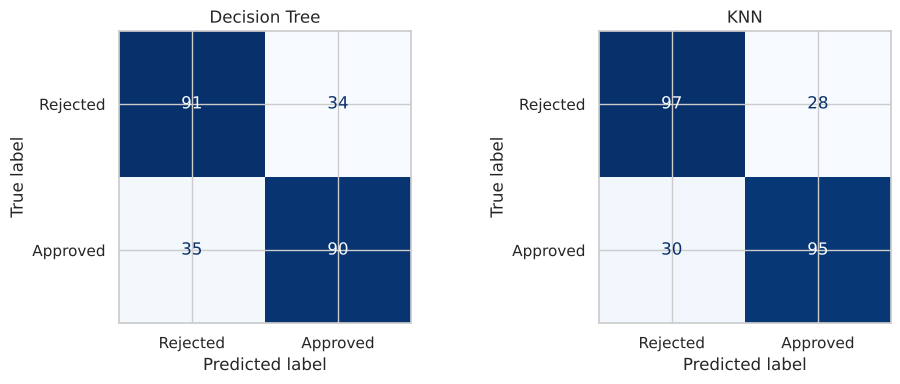

,Accuracy,Precision,Recall,F1-score
Model,,,,
Decision Tree,0.724,0.726,0.72,0.723
KNN,0.768,0.772,0.76,0.766


In [38]:
dt20 = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_train, y_train)
knn20 = KNeighborsClassifier(n_neighbors=7).fit(X_train_scaled, y_train)

pred_dt20 = dt20.predict(X_test)
pred_knn20 = knn20.predict(X_test_scaled)

results20 = [
    evaluate_model("Decision Tree", y_test, pred_dt20),
    evaluate_model("KNN", y_test, pred_knn20),
]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_confusion("Decision Tree", y_test, pred_dt20, axes[0])
plot_confusion("KNN", y_test, pred_knn20, axes[1])
plt.tight_layout(); plt.show()

pd.DataFrame(results20).set_index("Model").round(3)


### Problem Statement 21: Loan Approval Prediction using Naïve Bayes and SVM
Implement **Naïve Bayes** and **SVM** classifiers and compare their performance in
predicting approved and rejected loan applications.


--- Naive Bayes ---
Accuracy : 0.772
Precision: 0.739
Recall   : 0.840
F1-score : 0.787

--- SVM ---
Accuracy : 0.792
Precision: 0.812
Recall   : 0.760
F1-score : 0.785



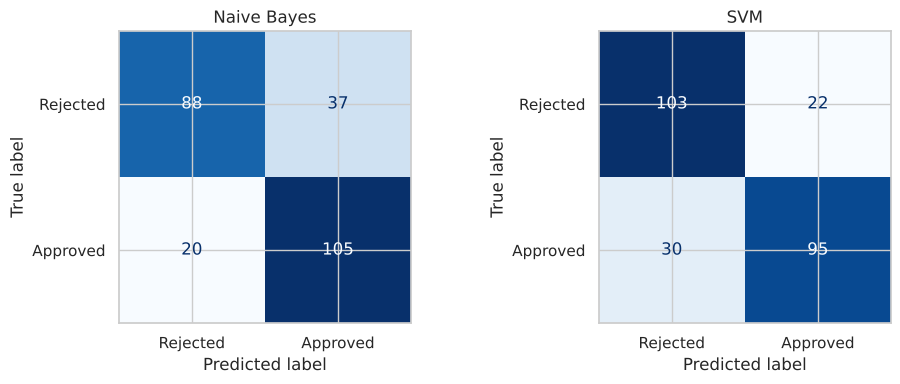

,Accuracy,Precision,Recall,F1-score
Model,,,,
Naive Bayes,0.772,0.739,0.84,0.787
SVM,0.792,0.812,0.76,0.785


In [39]:
nb21 = GaussianNB().fit(X_train_scaled, y_train)
svm21 = SVC(kernel="rbf", random_state=42).fit(X_train_scaled, y_train)

pred_nb21 = nb21.predict(X_test_scaled)
pred_svm21 = svm21.predict(X_test_scaled)

results21 = [
    evaluate_model("Naive Bayes", y_test, pred_nb21),
    evaluate_model("SVM", y_test, pred_svm21),
]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_confusion("Naive Bayes", y_test, pred_nb21, axes[0])
plot_confusion("SVM", y_test, pred_svm21, axes[1])
plt.tight_layout(); plt.show()

pd.DataFrame(results21).set_index("Model").round(3)


### Problem Statement 22: Loan Approval Prediction using Naïve Bayes and KNN
Train **Naïve Bayes** and **K-Nearest Neighbors (KNN)** classifiers and evaluate their
performance using suitable classification metrics.


--- Naive Bayes ---
Accuracy : 0.772
Precision: 0.739
Recall   : 0.840
F1-score : 0.787

--- KNN ---
Accuracy : 0.768
Precision: 0.772
Recall   : 0.760
F1-score : 0.766



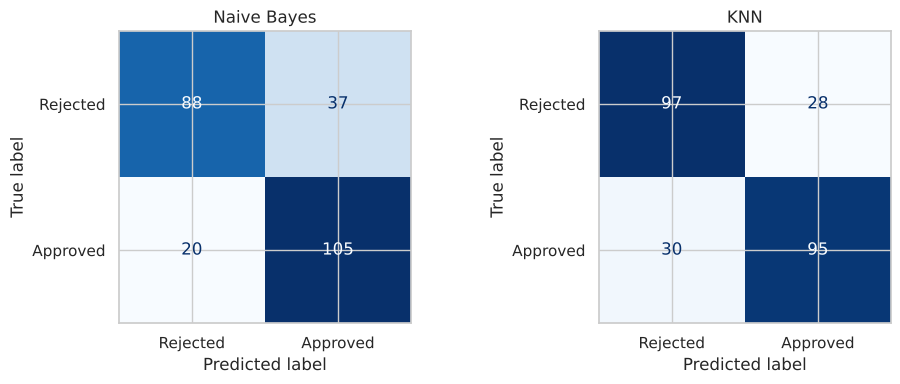

,Accuracy,Precision,Recall,F1-score
Model,,,,
Naive Bayes,0.772,0.739,0.84,0.787
KNN,0.768,0.772,0.76,0.766


In [40]:
nb22 = GaussianNB().fit(X_train_scaled, y_train)
knn22 = KNeighborsClassifier(n_neighbors=7).fit(X_train_scaled, y_train)

pred_nb22 = nb22.predict(X_test_scaled)
pred_knn22 = knn22.predict(X_test_scaled)

results22 = [
    evaluate_model("Naive Bayes", y_test, pred_nb22),
    evaluate_model("KNN", y_test, pred_knn22),
]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_confusion("Naive Bayes", y_test, pred_nb22, axes[0])
plot_confusion("KNN", y_test, pred_knn22, axes[1])
plt.tight_layout(); plt.show()

pd.DataFrame(results22).set_index("Model").round(3)


---
## Summary: All Loan-Approval Classifier Comparisons (PS17–22)


In [41]:
summary_rows = []
for label, rows in [
    ("PS17 (DT vs NB)", results17),
    ("PS18 (SVM vs KNN)", results18),
    ("PS19 (DT vs SVM)", results19),
    ("PS20 (DT vs KNN)", results20),
    ("PS21 (NB vs SVM)", results21),
    ("PS22 (NB vs KNN)", results22),
]:
    for r in rows:
        summary_rows.append({"Problem": label, **r})

summary_df = pd.DataFrame(summary_rows)
summary_df.round(3)


,Problem,Model,Accuracy,Precision,Recall,F1-score
0,PS17 (DT vs NB),Decision Tree,0.724,0.726,0.72,0.723
1,PS17 (DT vs NB),Naive Bayes,0.772,0.739,0.84,0.787
2,PS18 (SVM vs KNN),SVM,0.792,0.812,0.76,0.785
3,PS18 (SVM vs KNN),KNN,0.768,0.772,0.76,0.766
4,PS19 (DT vs SVM),Decision Tree,0.724,0.726,0.72,0.723
5,PS19 (DT vs SVM),SVM,0.792,0.812,0.76,0.785
6,PS20 (DT vs KNN),Decision Tree,0.724,0.726,0.72,0.723
7,PS20 (DT vs KNN),KNN,0.768,0.772,0.76,0.766
8,PS21 (NB vs SVM),Naive Bayes,0.772,0.739,0.84,0.787
9,PS21 (NB vs SVM),SVM,0.792,0.812,0.76,0.785


**Overall explanation:** All six problem statements reuse the same train/test split
of the synthetic loan dataset so the classifier pairs are compared fairly. Tree-based
and distance/probability-based models are evaluated with accuracy, precision, recall,
F1-score and a confusion matrix — precision/recall separate "wrongly approved" (risk to
the bank) from "wrongly rejected" (lost business) errors, which a single accuracy figure
would hide.
